In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

In [110]:
#df = pd.read_csv(r"C:\Users\Administrator\Downloads\AnalystLab_Africa_Week6_Batch_F_Assignment\S&P 500 Stock Prices 2014-2017.csv")

In [3]:
df

,symbol,date,open,high,low,close,volume
0,AAL,1/2/2014,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,1/2/2014,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,1/2/2014,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,1/2/2014,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,1/2/2014,70.1100,70.2300,69.4800,69.8900,1148391
...,...,...,...,...,...,...,...
497467,XYL,12/29/2017,68.5300,68.8000,67.9200,68.2000,1046677
497468,YUM,12/29/2017,82.6400,82.7100,81.5900,81.6100,1347613
497469,ZBH,12/29/2017,121.7500,121.9500,120.6200,120.6700,1023624
497470,ZION,12/29/2017,51.2800,51.5500,50.8100,50.8300,1261916


In [4]:
df.shape

(497472, 7)

In [5]:
df.columns

Index(['symbol', 'date', 'open', 'high', 'low', 'close', 'volume'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  object 
 1   date    497472 non-null  object 
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 26.6+ MB


In [7]:
df.describe()

,open,high,low,close,volume
count,497461.000000,497464.000000,497464.000000,497472.000000,4.974720e+05
mean,86.352275,87.132562,85.552467,86.369082,4.253611e+06
std,101.471228,102.312062,100.570957,101.472407,8.232139e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


In [8]:
df.isnull().sum()

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Date range

df['date'].min(), df['date'].max()

('1/10/2014', '9/9/2016')

In [11]:
# How many different stocks are there

df['symbol'].nunique()

505

In [12]:
# view the symbols

df['symbol'].unique()

array(['AAL', 'AAPL', 'AAP', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE', 'ADI',
       'ADM', 'ADP', 'ADSK', 'ADS', 'AEE', 'AEP', 'AES', 'AET', 'AFL',
       'AGN', 'AIG', 'AIV', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK',
       'ALLE', 'ALL', 'ALXN', 'AMAT', 'AMD', 'AME', 'AMGN', 'AMG', 'AMP',
       'AMT', 'AMZN', 'ANDV', 'ANSS', 'ANTM', 'AON', 'AOS', 'APA', 'APC',
       'APD', 'APH', 'ARE', 'ARNC', 'ATVI', 'AVB', 'AVGO', 'AVY', 'AWK',
       'AXP', 'AYI', 'AZO', 'A', 'BAC', 'BAX', 'BA', 'BBT', 'BBY', 'BDX',
       'BEN', 'BF.B', 'BIIB', 'BK', 'BLK', 'BLL', 'BMY', 'BRK.B', 'BSX',
       'BWA', 'BXP', 'CAG', 'CAH', 'CAT', 'CA', 'CBG', 'CBOE', 'CBS',
       'CB', 'CCI', 'CCL', 'CDNS', 'CELG', 'CERN', 'CF', 'CHD', 'CHK',
       'CHRW', 'CHTR', 'CINF', 'CI', 'CLX', 'CL', 'CMA', 'CMCSA', 'CME',
       'CMG', 'CMI', 'CMS', 'CNC', 'CNP', 'COF', 'COG', 'COL', 'COO',
       'COP', 'COST', 'COTY', 'CPB', 'CRM', 'CSCO', 'CSX', 'CTAS', 'CTL',
       'CTSH', 'CTXS', 'CVS', 'CVX', 'CXO', 'C', 'DAL', 'D

In [13]:
# how many records belong to each stock

df['symbol'].value_counts()

symbol
AAL     1007
PRGO    1007
NVDA    1007
NUE     1007
NTRS    1007
        ... 
DXC      189
BHGE     126
BHF      117
DWDP      83
APTV      18
Name: count, Length: 505, dtype: int64

In [14]:
# Convert the date column

df['date'] = pd.to_datetime(df['date'])

In [15]:
# check the data type for the date column above

df['date'].dtype

dtype('<M8[ns]')

In [16]:
# check date range

df['date'].min(), df['date'].max()

(Timestamp('2014-01-02 00:00:00'), Timestamp('2017-12-29 00:00:00'))

In [17]:
# count the records for each stock

df['symbol'].value_counts().describe()

count     505.000000
mean      985.093069
std       118.785643
min        18.000000
25%      1007.000000
50%      1007.000000
75%      1007.000000
max      1007.000000
Name: count, dtype: float64

In [18]:
# identify the stocks with the fewest records

df['symbol'].value_counts().sort_values().head(10)

symbol
APTV     18
DWDP     83
BHF     117
BHGE    126
DXC     189
HLT     250
EVHC    271
FTV     378
UA      438
WLTW    502
Name: count, dtype: int64

In [19]:
# identify the stocks with the most records

df['symbol'].value_counts().sort_values(ascending=False).head(10)

symbol
AAL     1007
IVZ     1007
ABT     1007
ACN     1007
ADBE    1007
ADI     1007
ADM     1007
ADP     1007
ADSK    1007
ADS     1007
Name: count, dtype: int64

### Investigating zero-volume observations

In [20]:
# count zero-volume observations

(df['volume'] == 0).sum()

np.int64(4)

In [21]:
# Display the affected records

df[df['volume'] == 0]

,symbol,date,open,high,low,close,volume
249223,DHR,2016-01-12,NaN,NaN,NaN,88.55,0
249438,O,2016-01-12,NaN,NaN,NaN,52.43,0
278801,UA,2016-04-07,NaN,NaN,NaN,41.56,0
308365,FTV,2016-07-01,NaN,NaN,NaN,49.54,0


### Investigating unusual price observations

In [22]:
# zero or negative prices check

df[(df[['open', 'high', 'low', 'close']] <= 0).any(axis=1)]

,symbol,date,open,high,low,close,volume


In [23]:
# Check whether the highest price is below the lowest price

df[df['high'] < df['low']]

,symbol,date,open,high,low,close,volume
45501,AOS,2014-05-19,23.89,23.595,23.85,24.445,1944854


In [24]:
# Do the opening or closing prices fall outside the daily high-low range

df[
    (df['open'] > df['high']) |
    (df['open'] < df['low']) |
    (df['close'] > df['high']) |
    (df['close'] < df['low'])
]

,symbol,date,open,high,low,close,volume
45501,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854
45548,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888
48774,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759
59618,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836
60252,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981
79814,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518
103984,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419
104196,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132
269985,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794
291756,WRK,2016-05-13,42.450,42.8900,41.820,38.3900,2153541


### Sort the dataset chronologically

In [25]:
# Order by symbol and date

df = df.sort_values(['symbol', 'date'])

In [26]:
# reset the index

df = df.reset_index(drop=True)

In [27]:
# check the result

df.head()

,symbol,date,open,high,low,close,volume
0,A,2014-01-02,57.10,57.100,56.15,56.21,1916160
1,A,2014-01-03,56.39,57.345,56.26,56.92,1866651
2,A,2014-01-06,57.40,57.700,56.56,56.64,1777472
3,A,2014-01-07,56.95,57.630,56.93,57.45,1463208
4,A,2014-01-08,57.33,58.540,57.17,58.39,2659468


In [28]:
print("Dataset shape:", df.shape)
print("Unique stocks:", df['symbol'].nunique())
print("Date range:", df['date'].min(), "to", df['date'].max())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())
print("Duplicate stock-date combinations:", df.duplicated(subset=['symbol', 'date']).sum())
print("Zero-volume records:", (df['volume'] == 0).sum())

Dataset shape: (497472, 7)
Unique stocks: 505
Date range: 2014-01-02 00:00:00 to 2017-12-29 00:00:00
Missing values: 27
Duplicate records: 0
Duplicate stock-date combinations: 0
Zero-volume records: 4


In [29]:
# Display every row containing missing values

df[df.isnull().any(axis=1)]

,symbol,date,open,high,low,close,volume
66487,BHF,2017-07-26,NaN,NaN,NaN,69.0842,3
133913,DHR,2015-07-17,NaN,88.76,88.24,88.7200,2056819
134036,DHR,2016-01-12,NaN,NaN,NaN,88.5500,0
162370,ES,2015-07-17,NaN,48.49,47.85,47.9200,1246786
193471,FTV,2016-07-01,NaN,NaN,NaN,49.5400,0
343994,O,2015-07-17,NaN,47.31,46.83,46.9900,1229513
344117,O,2016-01-12,NaN,NaN,NaN,52.4300,0
386638,REGN,2015-06-09,NaN,NaN,NaN,526.0900,12135
446553,UA,2016-04-07,NaN,NaN,NaN,41.5600,0
468479,VRTX,2015-05-12,NaN,NaN,NaN,124.0800,569747


In [30]:
# Display the suspicious price records together

df[
    (df['high'] < df['low']) |
    (df['open'] > df['high']) |
    (df['open'] < df['low']) |
    (df['close'] > df['high']) |
    (df['close'] < df['low'])
]

,symbol,date,open,high,low,close,volume
43395,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854
63004,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794
91809,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888
92845,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836
133750,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419
242487,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981
281857,LNT,2016-05-19,35.190,35.7850,35.085,17.8700,1231722
343781,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518
343831,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132
413567,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759


In [31]:
# Create a backup

df_clean = df.copy()

### Data Cleaning

In [32]:
# Remove records with missing OHLC prices

df_clean = df_clean.dropna(subset=['open', 'high', 'low', 'close'])

In [33]:
# Reset the index

df_clean = df_clean.reset_index(drop=True)


In [34]:
# verify missing values

df_clean.isnull().sum()

symbol    0
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64

In [35]:
# Verify dataset dimensions

df_clean.shape

(497461, 7)

### Create analytical columns

In [36]:
# Extract Year, Month and Quarter

df_clean['year'] = df_clean['date'].dt.year

df_clean['month'] = df_clean['date'].dt.month

df_clean['quarter'] = df_clean['date'].dt.quarter

In [37]:
# Calculate Daily Price Change

df_clean['daily_price_change'] = df_clean.groupby('symbol')['close'].diff()

In [38]:
# Calculate Daily Percentage Return

df_clean['daily_return'] = df_clean.groupby('symbol')['close'].pct_change() * 100

In [39]:
# Calculate Trading Range

df_clean['trading_range'] = df_clean['high'] - df_clean['low']

In [40]:
# Calculate Moving Averages

df_clean['ma_7'] = df_clean.groupby('symbol')['close'].transform(
    lambda x: x.rolling(window=7).mean()
)

df_clean['ma_30'] = df_clean.groupby('symbol')['close'].transform(
    lambda x: x.rolling(window=30).mean()
)


In [41]:
# Inspect the prepared dataset
df_clean.head(10)

,symbol,date,open,high,low,close,volume,year,month,quarter,daily_price_change,daily_return,trading_range,ma_7,ma_30
0,A,2014-01-02,57.10,57.100,56.150,56.21,1916160,2014,1,1,NaN,NaN,0.950,NaN,NaN
1,A,2014-01-03,56.39,57.345,56.260,56.92,1866651,2014,1,1,0.71,1.263120,1.085,NaN,NaN
2,A,2014-01-06,57.40,57.700,56.560,56.64,1777472,2014,1,1,-0.28,-0.491918,1.140,NaN,NaN
3,A,2014-01-07,56.95,57.630,56.930,57.45,1463208,2014,1,1,0.81,1.430085,0.700,NaN,NaN
4,A,2014-01-08,57.33,58.540,57.170,58.39,2659468,2014,1,1,0.94,1.636205,1.370,NaN,NaN
5,A,2014-01-09,58.40,58.680,57.870,58.41,1757647,2014,1,1,0.02,0.034252,0.810,NaN,NaN
6,A,2014-01-10,58.51,59.010,58.140,58.93,1623330,2014,1,1,0.52,0.890259,0.870,57.564286,NaN
7,A,2014-01-13,58.77,59.100,58.600,58.93,2946738,2014,1,1,0.00,0.000000,0.500,57.952857,NaN
8,A,2014-01-14,59.16,59.950,59.020,59.88,2562236,2014,1,1,0.95,1.612082,0.930,58.375714,NaN
9,A,2014-01-15,59.82,60.365,59.585,60.34,2335194,2014,1,1,0.46,0.768203,0.780,58.904286,NaN


In [42]:
# inspect the new columns

df_clean[['symbol', 'date', 'close', 'daily_price_change',
          'daily_return', 'trading_range', 'ma_7', 'ma_30']].head(35)

,symbol,date,close,daily_price_change,daily_return,trading_range,ma_7,ma_30
0,A,2014-01-02,56.21,NaN,NaN,0.9500,NaN,NaN
1,A,2014-01-03,56.92,0.71,1.263120,1.0850,NaN,NaN
2,A,2014-01-06,56.64,-0.28,-0.491918,1.1400,NaN,NaN
3,A,2014-01-07,57.45,0.81,1.430085,0.7000,NaN,NaN
4,A,2014-01-08,58.39,0.94,1.636205,1.3700,NaN,NaN
5,A,2014-01-09,58.41,0.02,0.034252,0.8100,NaN,NaN
6,A,2014-01-10,58.93,0.52,0.890259,0.8700,57.564286,NaN
7,A,2014-01-13,58.93,0.00,0.000000,0.5000,57.952857,NaN
8,A,2014-01-14,59.88,0.95,1.612082,0.9300,58.375714,NaN
9,A,2014-01-15,60.34,0.46,0.768203,0.7800,58.904286,NaN


In [43]:
# Check the new dataset structure

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497461 entries, 0 to 497460
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   symbol              497461 non-null  object        
 1   date                497461 non-null  datetime64[ns]
 2   open                497461 non-null  float64       
 3   high                497461 non-null  float64       
 4   low                 497461 non-null  float64       
 5   close               497461 non-null  float64       
 6   volume              497461 non-null  int64         
 7   year                497461 non-null  int32         
 8   month               497461 non-null  int32         
 9   quarter             497461 non-null  int32         
 10  daily_price_change  496956 non-null  float64       
 11  daily_return        496956 non-null  float64       
 12  trading_range       497461 non-null  float64       
 13  ma_7                494431 no

In [44]:
#  Flag unusual price records

df_clean['price_anomaly'] = (
    (df_clean['high'] < df_clean['low']) |
    (df_clean['open'] > df_clean['high']) |
    (df_clean['open'] < df_clean['low']) |
    (df_clean['close'] > df_clean['high']) |
    (df_clean['close'] < df_clean['low'])
)

In [45]:
# Count the flagged records

df_clean['price_anomaly'].sum()

np.int64(12)

In [46]:
df_clean[df_clean['price_anomaly']]

,symbol,date,open,high,low,close,volume,year,month,quarter,daily_price_change,daily_return,trading_range,ma_7,ma_30,price_anomaly
43395,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854,2014,5,2,0.5300,2.216182,-0.2550,23.911429,23.350167,True
63004,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794,2016,3,1,-1.4000,-4.103165,0.6700,33.900000,30.935667,True
91808,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888,2014,5,2,0.0250,0.073812,0.2575,33.882857,34.180833,True
92844,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836,2014,6,2,-1.0100,-3.322368,0.7300,30.541429,29.585333,True
133749,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419,2014,11,4,0.4900,0.606661,0.8150,80.578571,76.242667,True
242482,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981,2014,7,3,-0.3800,-0.752923,0.5000,49.172857,48.039000,True
281852,LNT,2016-05-19,35.190,35.7850,35.085,17.8700,1231722,2016,5,2,-17.4800,-49.448373,0.7000,33.832857,35.361000,True
343776,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518,2014,8,3,-0.2328,-0.520107,0.0400,45.039600,44.478907,True
343826,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132,2014,11,4,-0.4100,-0.867358,0.8400,46.880000,43.840333,True
413559,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759,2014,5,2,-11.1300,-6.304163,2.1000,173.784286,173.196667,True


In [47]:
df_clean.isnull().sum()

symbol                    0
date                      0
open                      0
high                      0
low                       0
close                     0
volume                    0
year                      0
month                     0
quarter                   0
daily_price_change      505
daily_return            505
trading_range             0
ma_7                   3030
ma_30                 14634
price_anomaly             0
dtype: int64

In [48]:
# anomaly cunt

df_clean['price_anomaly'].value_counts()

price_anomaly
False    497449
True         12
Name: count, dtype: int64

In [49]:
# No. of records per stock

df_clean.groupby('symbol').size().describe()

count     505.000000
mean      985.071287
std       118.823778
min        18.000000
25%      1007.000000
50%      1007.000000
75%      1007.000000
max      1007.000000
dtype: float64

In [50]:
#  Confirm chronological sorting

df_clean[['symbol', 'date']].head(10)

,symbol,date
0,A,2014-01-02
1,A,2014-01-03
2,A,2014-01-06
3,A,2014-01-07
4,A,2014-01-08
5,A,2014-01-09
6,A,2014-01-10
7,A,2014-01-13
8,A,2014-01-14
9,A,2014-01-15


In [51]:
df_clean.shape

(497461, 16)

### Exploratory Data Analysis (EDA)

In [52]:
# understanding how the dataset is distributed across the four years

# Number of records per year
df_clean['year'].value_counts().sort_index()

# Average closing price and trading volume by year
yearly_market = df_clean.groupby('year').agg(
    average_closing_price=('close', 'mean'),
    average_trading_volume=('volume', 'mean'),
    total_trading_volume=('volume', 'sum')
)

yearly_market


,average_closing_price,average_trading_volume,total_trading_volume
year,,,
2014,76.969836,4.163922e+06,509651540155
2015,84.131558,4.324119e+06,534949672248
2016,85.253965,4.556700e+06,571045692991
2017,98.800548,3.970454e+06,500400300042


In [53]:
# Average daily return by year
df_clean.groupby('year')['daily_return'].mean()

year
2014    0.063969
2015   -0.001365
2016    0.056250
2017    0.064981
Name: daily_return, dtype: float64

### yearly market trends visualization

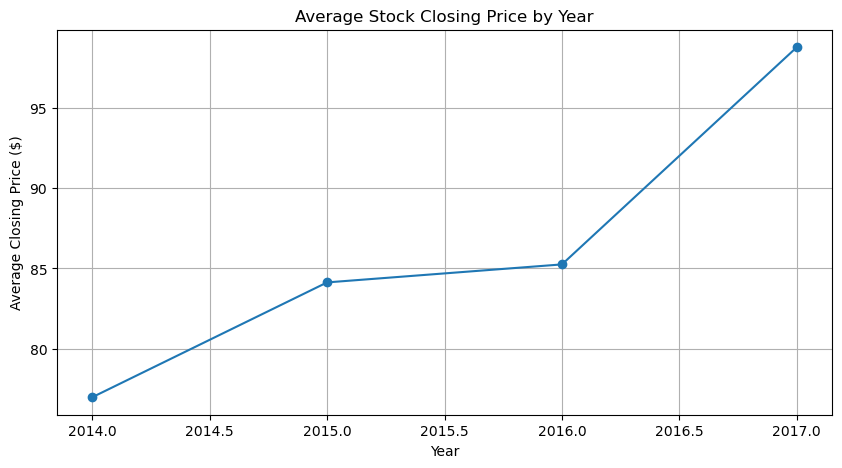

In [54]:
# Average closing price by year

yearly_market['average_closing_price'].plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Average Stock Closing Price by Year'
)

plt.xlabel('Year')
plt.ylabel('Average Closing Price ($)')
plt.grid()
plt.show()

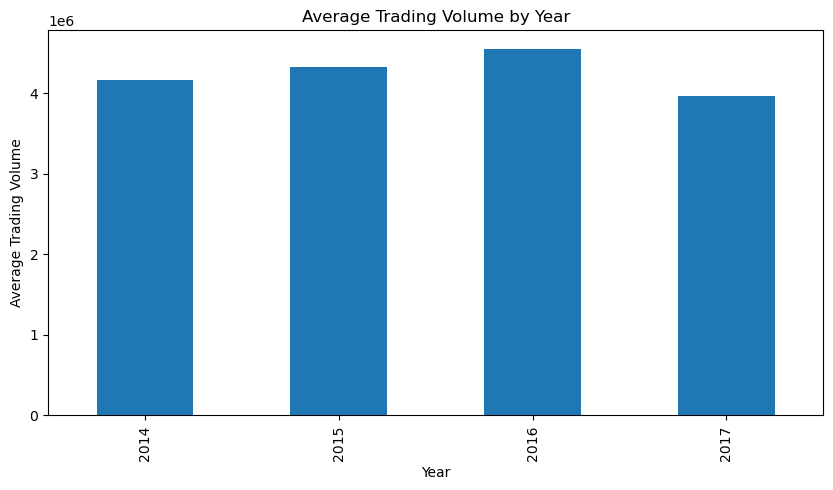

In [55]:
# Average trading volume by year

yearly_market['average_trading_volume'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Average Trading Volume by Year'
)

plt.xlabel('Year')
plt.ylabel('Average Trading Volume')
plt.show()

In [56]:
# Average closing price for each stock
stock_prices = df_clean.groupby('symbol')['close'].mean().sort_values(ascending=False)

# Top 10 stocks
stock_prices.head(10)

symbol
PCLN     1390.272642
GOOGL     722.559017
GOOG      714.496848
AZO       660.246425
AMZN      619.244787
CMG       516.849355
REGN      412.222746
MTD       377.854131
BLK       359.971301
BIIB      310.474882
Name: close, dtype: float64

In [57]:
# Bottom 10 stocks
stock_prices.tail(10)

symbol
NAVI    15.410645
KEY     14.633674
NWS     14.476157
NWSA    14.411974
F       13.832264
AES     12.210854
CHK     11.758113
RF      11.135209
HBAN    11.049269
AMD      5.908605
Name: close, dtype: float64

#### Stock performance comparison

In [58]:
# Summary statistics for each stock
stock_summary = df_clean.groupby('symbol').agg(
    average_closing_price=('close', 'mean'),
    average_daily_return=('daily_return', 'mean'),
    return_volatility=('daily_return', 'std'),
    average_trading_volume=('volume', 'mean')
)

stock_summary.head()

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
A,49.097726,0.030631,1.578743,2.191932e+06
AAL,42.424900,0.096502,2.238868,9.751521e+06
AAP,143.187120,0.009560,1.947149,1.137307e+06
AAPL,116.839892,0.085956,1.430893,4.516957e+07
ABBV,63.338302,0.075260,1.643618,8.408836e+06


In [59]:
# stocks with the highest average closing prices

stock_summary.sort_values(
    by='average_closing_price',
    ascending=False
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
PCLN,1390.272642,0.055613,1.675959,6.329282e+05
GOOGL,722.559017,0.072758,1.382401,2.107184e+06
GOOG,714.496848,0.075846,1.395773,1.809883e+06
AZO,660.246425,0.048812,1.296479,3.211770e+05
AMZN,619.244787,0.124430,1.864574,3.880125e+06
CMG,516.849355,-0.040175,1.934326,9.020612e+05
REGN,412.222746,0.055528,2.216177,8.794497e+05
MTD,377.854131,0.103182,1.382723,1.719199e+05
BLK,359.971301,0.057940,1.312217,6.205323e+05


In [60]:
# stocks with the lowest average closing prices

stock_summary.sort_values(
    by='average_closing_price'
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
AMD,5.908605,0.168442,3.910169,3.328951e+07
HBAN,11.049269,0.053844,1.535409,1.035622e+07
RF,11.135209,0.069880,1.695516,1.674565e+07
CHK,11.758113,-0.086530,4.551547,2.788540e+07
AES,12.210854,-0.014631,1.597822,5.489659e+06
F,13.832264,-0.011410,1.386585,3.291430e+07
NWSA,14.411974,0.001894,1.551256,3.020695e+06
NWS,14.476157,0.003859,1.504807,9.496257e+05
KEY,14.633674,0.054186,1.592911,1.185261e+07


In [61]:
# stocks with the highest average daily returns

stock_summary.sort_values(
    by='average_daily_return',
    ascending=False
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
NVDA,61.364663,0.276020,2.373885,1.076129e+07
DXC,84.023651,0.185460,1.244895,2.038838e+06
AVGO,148.079095,0.177969,2.023737,2.889738e+06
EA,68.958583,0.169227,1.889932,3.551909e+06
AMD,5.908605,0.168442,3.910169,3.328951e+07
NFLX,104.138074,0.165104,2.658549,1.437372e+07
ALGN,88.490892,0.154462,1.960721,8.819067e+05
SWKS,77.094004,0.148829,2.249636,3.205762e+06
CNC,61.609181,0.144794,2.111690,1.717232e+06


In [62]:
# stocks with the lowest average daily returns

stock_summary.sort_values(
    by='average_daily_return'
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
BHGE,33.962302,-0.396924,3.661471,3.864731e+06
APTV,85.100000,-0.257371,1.400067,2.017036e+06
UA,24.301281,-0.231825,2.824901,3.254515e+06
EVHC,54.217731,-0.210633,2.955314,2.251498e+06
BHF,59.465403,-0.140023,1.658820,1.057476e+06
RRC,45.564777,-0.113508,2.907283,4.187862e+06
DISCA,36.170834,-0.099924,2.456712,3.405332e+06
DISCK,34.620253,-0.098441,2.423206,1.962737e+06
MAT,28.350551,-0.089325,2.117745,5.305117e+06


In [63]:
# stocks with the highest return volatility

stock_summary.sort_values(
    by='return_volatility',
    ascending=False
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
CHK,11.758113,-0.086530,4.551547,2.788540e+07
AMD,5.908605,0.168442,3.910169,3.328951e+07
LNT,34.270348,0.106771,3.700607,1.280132e+06
FCX,18.205968,-0.000526,3.698899,2.561982e+07
BHGE,33.962302,-0.396924,3.661471,3.864731e+06
WMB,36.926763,0.030095,3.234744,8.361433e+06
MRO,21.491306,-0.020947,3.216357,1.312908e+07
EVHC,54.217731,-0.210633,2.955314,2.251498e+06
RRC,45.564777,-0.113508,2.907283,4.187862e+06


In [64]:
# stocks with the highest average trading volumes

stock_summary.sort_values(
    by='average_trading_volume',
    ascending=False
).head(10)

,average_closing_price,average_daily_return,return_volatility,average_trading_volume
symbol,,,,
BAC,18.263083,0.073270,1.611274,8.936290e+07
AAPL,116.839892,0.085956,1.430893,4.516957e+07
GE,27.279270,-0.038201,1.184772,4.144394e+07
AMD,5.908605,0.168442,3.910169,3.328951e+07
F,13.832264,-0.011410,1.386585,3.291430e+07
MSFT,54.084863,0.092242,1.369469,3.071261e+07
FB,107.738043,0.131298,1.732675,2.922782e+07
MU,24.445754,0.102147,2.770437,2.796281e+07
CHK,11.758113,-0.086530,4.551547,2.788540e+07


### Market trends over time

In [65]:
# Monthly market trends
monthly_market = df_clean.groupby(
    df_clean['date'].dt.to_period('M')
).agg(
    average_closing_price=('close', 'mean'),
    average_trading_volume=('volume', 'mean')
)

monthly_market.head()

,average_closing_price,average_trading_volume
date,,
2014-01,71.825667,4.954679e+06
2014-02,72.859147,4.918515e+06
2014-03,74.899410,4.424686e+06
2014-04,74.578316,4.712437e+06
2014-05,75.317910,3.755789e+06


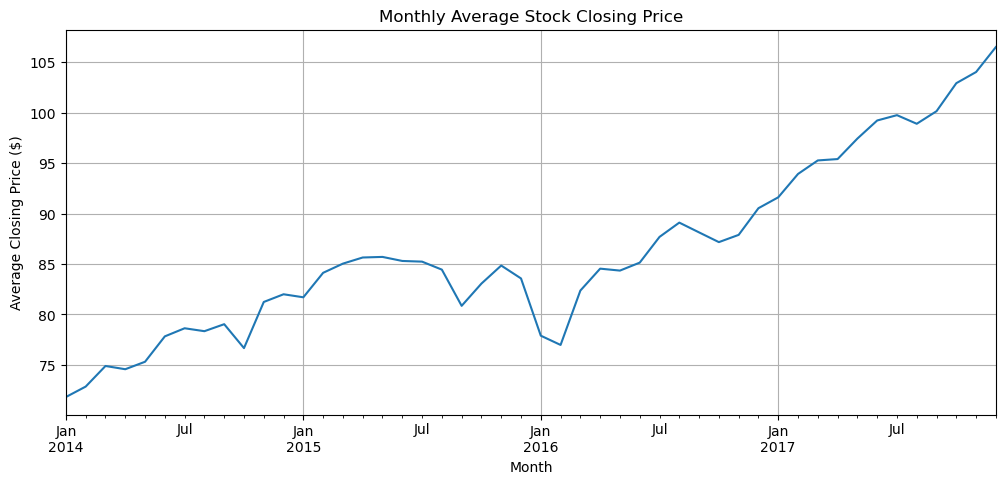

In [66]:
# Average closing price

monthly_market['average_closing_price'].plot(
    figsize=(12, 5),
    title='Monthly Average Stock Closing Price'
)

plt.xlabel('Month')
plt.ylabel('Average Closing Price ($)')
plt.grid()
plt.show()

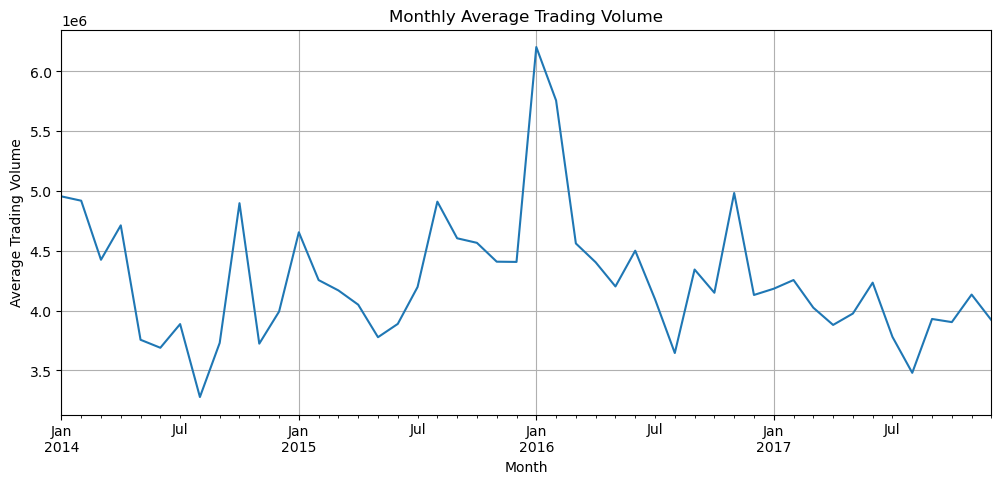

In [67]:
# average trading volume

monthly_market['average_trading_volume'].plot(
    figsize=(12, 5),
    title='Monthly Average Trading Volume'
)

plt.xlabel('Month')
plt.ylabel('Average Trading Volume')
plt.grid()
plt.show()

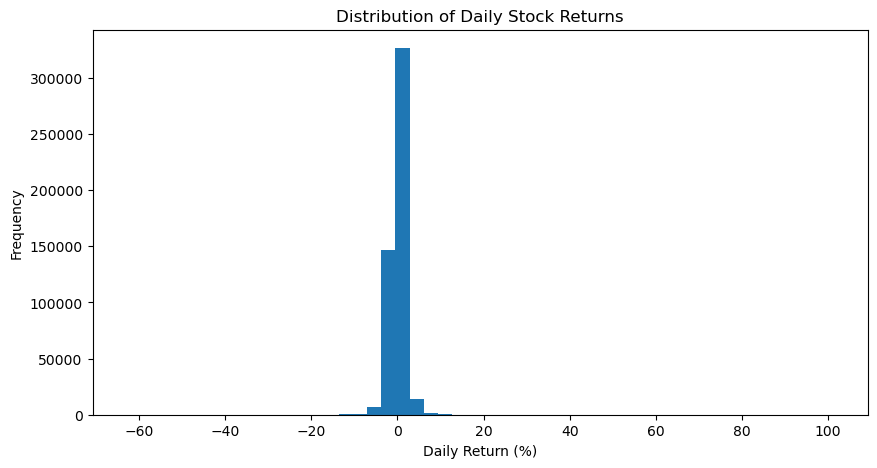

In [68]:
# Daily return distribution

df_clean['daily_return'].dropna().plot(
    kind='hist',
    bins=50,
    figsize=(10, 5),
    title='Distribution of Daily Stock Returns'
)

plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency')
plt.show()

### Compare five selected stocks

In [69]:
# Select the five stocks with the highest average trading volume
top_5_symbols = stock_summary.sort_values(
    by='average_trading_volume',
    ascending=False
).head(5).index.tolist()

top_5_symbols

['BAC', 'AAPL', 'GE', 'AMD', 'F']

In [70]:
# Extract closing prices for the selected stocks
comparison = df_clean[
    df_clean['symbol'].isin(top_5_symbols)
].pivot(
    index='date',
    columns='symbol',
    values='close'
)

comparison.head()

symbol,AAPL,AMD,BAC,F,GE
date,,,,,
2014-01-02,79.0185,3.95,16.10,15.44,27.50
2014-01-03,77.2828,4.00,16.41,15.51,27.48
2014-01-06,77.7042,4.13,16.66,15.58,27.26
2014-01-07,77.1481,4.18,16.50,15.38,27.29
2014-01-08,77.6371,4.18,16.58,15.54,27.21


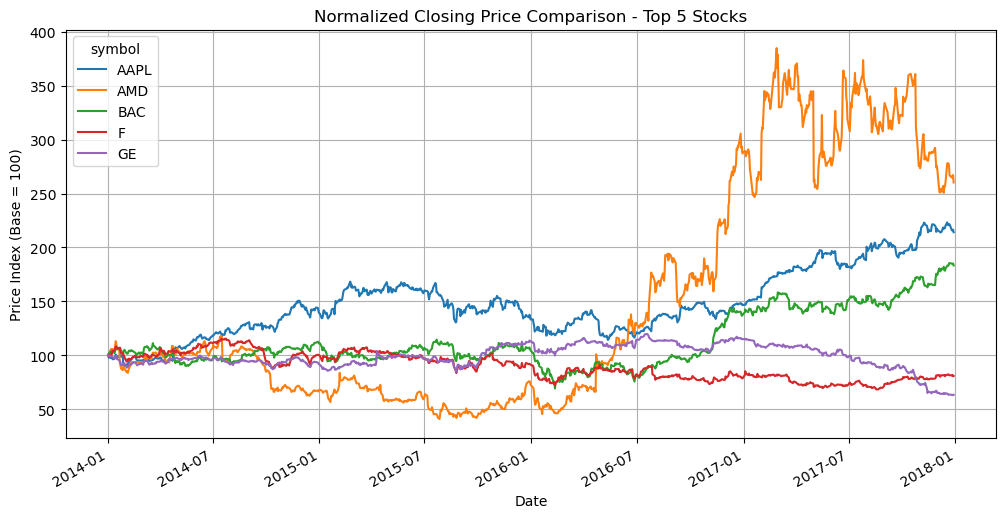

In [71]:
# Normalize stock prices to a base of 100
normalized_prices = comparison.apply(
    lambda x: x / x.dropna().iloc[0] * 100
)

normalized_prices.plot(
    figsize=(12, 6),
    title='Normalized Closing Price Comparison - Top 5 Stocks'
)

plt.xlabel('Date')
plt.ylabel('Price Index (Base = 100)')
plt.grid()
plt.show()

In [72]:
# Final normalized price index for the five stocks
normalized_prices.iloc[-1].sort_values(ascending=False)

symbol
AMD     260.253165
AAPL    214.165037
BAC     183.354037
F        80.893782
GE       63.454545
Name: 2017-12-29 00:00:00, dtype: float64

In [73]:
# Count flagged and normal records
df_clean['price_anomaly'].value_counts()

price_anomaly
False    497449
True         12
Name: count, dtype: int64

In [74]:
# Display records with unusual OHLC values
df_clean[df_clean['price_anomaly']][
    ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']
]

,symbol,date,open,high,low,close,volume
43395,AOS,2014-05-19,23.890,23.5950,23.850,24.4450,1944854
63004,BBY,2016-03-14,33.550,33.7500,33.080,32.7200,6037794
91808,CHD,2014-05-19,18.770,33.9525,33.695,33.8950,1078888
92844,CHK,2014-06-30,30.430,31.1000,30.370,29.3900,8132836
133749,DHR,2014-11-06,78.470,81.3050,80.490,81.2600,1614419
242482,IP,2014-07-01,50.850,51.0700,50.570,50.0900,5624981
281852,LNT,2016-05-19,35.190,35.7850,35.085,17.8700,1231722
343776,O,2014-08-27,44.675,44.7000,44.660,44.5272,185518
343826,O,2014-11-06,44.740,47.5700,46.730,46.8600,1803132
413559,SPG,2014-05-28,176.230,176.6000,174.500,165.4200,1383759


## Dashboard

In [75]:
# Market overview KPIs

total_symbols = df_clean['symbol'].nunique()

total_records = len(df_clean)

start_date = df_clean['date'].min().strftime('%Y-%m-%d')
end_date = df_clean['date'].max().strftime('%Y-%m-%d')

average_closing_price = df_clean['close'].mean()

print("Total Stock Symbols:", total_symbols)
print("Total Trading Records:", total_records)
print("Available Date Range:", start_date, "to", end_date)
print("Average Closing Price:", round(average_closing_price, 2))

Total Stock Symbols: 505
Total Trading Records: 497461
Available Date Range: 2014-01-02 to 2017-12-29
Average Closing Price: 86.37


In [76]:
# Selected stocks for dashboard comparison
dashboard_stocks = top_5_symbols

dashboard_data = df_clean[
    df_clean['symbol'].isin(dashboard_stocks)
].copy()

dashboard_data.head()

,symbol,date,open,high,low,close,volume,year,month,quarter,daily_price_change,daily_return,trading_range,ma_7,ma_30,price_anomaly
3021,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957,2014,1,1,NaN,NaN,0.7155,NaN,NaN,False
3022,AAPL,2014-01-03,78.9799,79.0999,77.2042,77.2828,98303870,2014,1,1,-1.7357,-2.196574,1.8957,NaN,NaN,False
3023,AAPL,2014-01-06,76.7785,78.1142,76.2285,77.7042,103359151,2014,1,1,0.4214,0.545270,1.8857,NaN,NaN,False
3024,AAPL,2014-01-07,77.7599,77.9942,76.8464,77.1481,79432766,2014,1,1,-0.5561,-0.715663,1.1478,NaN,NaN,False
3025,AAPL,2014-01-08,76.9728,77.9371,76.9556,77.6371,64686685,2014,1,1,0.4890,0.633846,0.9815,NaN,NaN,False


### Dashboard 1 | Market Overview

In [98]:
average_closing_price = dashboard_data['close'].mean()

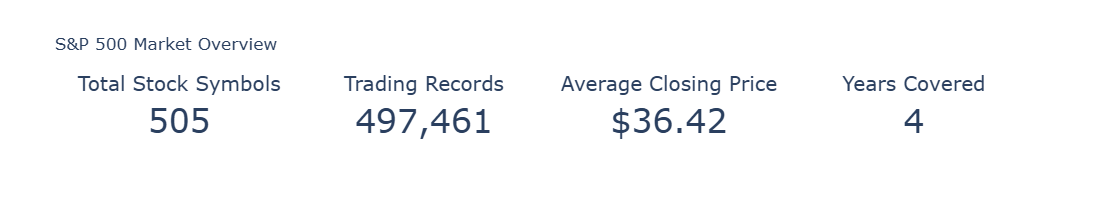

In [99]:
# KPIs

from plotly.subplots import make_subplots

kpi_fig = make_subplots(
    rows=1,
    cols=4,
    specs=[[{"type": "indicator"}] * 4]
)

kpi_fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_symbols,
        title={"text": "Total Stock Symbols"}
    ),
    row=1, col=1
)

kpi_fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_records,
        title={"text": "Trading Records"},
        number={"valueformat": ",.0f"}
    ),
    row=1, col=2
)

kpi_fig.add_trace(
    go.Indicator(
        mode="number",
        value=average_closing_price,
        title={"text": "Average Closing Price"},
        number={"prefix": "$", "valueformat": ".2f"}
    ),
    row=1, col=3
)

kpi_fig.add_trace(
    go.Indicator(
        mode="number",
        value=4,
        title={"text": "Years Covered"}
    ),
    row=1, col=4
)

kpi_fig.update_layout(
    title="S&P 500 Market Overview",
    height=220
)

kpi_fig.show()

In [78]:
# Top 10 stocks by number of trading records

symbol_counts = df_clean['symbol'].value_counts().head(10)

fig = px.bar(
    x=symbol_counts.index,
    y=symbol_counts.values,
    title='Top 10 Stocks by Trading Records',
    labels={
        'x': 'Stock Symbol',
        'y': 'Number of Records'
    }
)

fig.show()

In [79]:
# General market overview 

fig = px.line(
    yearly_market,
    x=yearly_market.index,
    y='average_closing_price',
    markers=True,
    title='Average Closing Price by Year',
    labels={
        'year': 'Year',
        'average_closing_price': 'Average Closing Price ($)'
    }
)

fig.show()

In [80]:
fig = px.bar(
    yearly_market,
    x=yearly_market.index,
    y='average_trading_volume',
    title='Average Trading Volume by Year',
    labels={
        'year': 'Year',
        'average_trading_volume': 'Average Trading Volume'
    }
)

fig.show()

### Dashboard 2 | Stock Price Performance

In [81]:
average_closing_price = dashboard_data['close'].mean()

In [82]:
# Closing price trends

fig = px.line(
    dashboard_data,
    x='date',
    y='close',
    color='symbol',
    title='Closing Price Trends Of Selected Stocks'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(
    height=700,
    xaxis_title='Date',
    yaxis_title='Closing Price ($)'
)

fig.show()

In [83]:
#Opening, highest and lowest prices

selected_stock = dashboard_stocks[0]

stock_data = dashboard_data[
    dashboard_data['symbol'] == selected_stock
]

fig = px.line(
    stock_data,
    x='date',
    y=['open', 'high', 'low'],
    title=f'Opening, Highest and Lowest Prices - {selected_stock}'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(
    height=700)
fig.show()

In [85]:
#Daily price movements
fig = px.line(
    stock_data,
    x='date',
    y='daily_price_change',
    title=f'Daily Price Changes - {selected_stock}'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(height = 700)
fig.show()

In [86]:
#Moving averages
fig = px.line(
    stock_data,
    x='date',
    y=['close', 'ma_7', 'ma_30'],
    title=f'Closing Price and Moving Averages - {selected_stock}'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(height=700)
fig.show()

### Dashboard 3 | Returns and Volatility

In [87]:
#Daily percentage returns
fig = px.line(
    dashboard_data,
    x='date',
    y='daily_return',
    color='symbol',
    title='Daily Percentage Returns - Selected Stocks'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(height=700)
fig.show()

In [88]:
#Average daily returns
average_returns = (
    dashboard_data.groupby('symbol')['daily_return']
    .mean()
    .reset_index()
)

fig = px.bar(
    average_returns,
    x='symbol',
    y='daily_return',
    title='Average Daily Returns by Stock',
    labels={
        'symbol': 'Stock Symbol',
        'daily_return': 'Average Daily Return (%)'
    }
)
fig.update_layout(height=700)
fig.show()

In [89]:

#Return distribution
fig = px.histogram(
    dashboard_data,
    x='daily_return',
    color='symbol',
    nbins=50,
    title='Daily Return Distribution - Selected Stocks'
)


fig.update_layout(height=700)
fig.show()

In [90]:
#Historical volatility
volatility = (
    dashboard_data.groupby('symbol')['daily_return']
    .std()
    .reset_index(name='volatility')
)

fig = px.bar(
    volatility,
    x='symbol',
    y='volatility',
    title='Historical Volatility by Stock',
    labels={
        'symbol': 'Stock Symbol',
        'volatility': 'Standard Deviation of Daily Returns (%)'
    }
)

fig.update_layout(height=700)
fig.show()

### Dashboard 4 | Trading Volume Analysis

In [91]:
#Trading volume trends
fig = px.line(
    dashboard_data,
    x='date',
    y='volume',
    color='symbol',
    title='Trading Volume Trends Of Selected Stocks'
)

fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(height = 700)
fig.show()

In [92]:
#Average trading volume
average_volume = (
    dashboard_data.groupby('symbol')['volume']
    .mean()
    .reset_index()
)

fig = px.bar(
    average_volume,
    x='symbol',
    y='volume',
    title='Average Trading Volume by Stock'
)

fig.update_layout(height = 700)
fig.show()

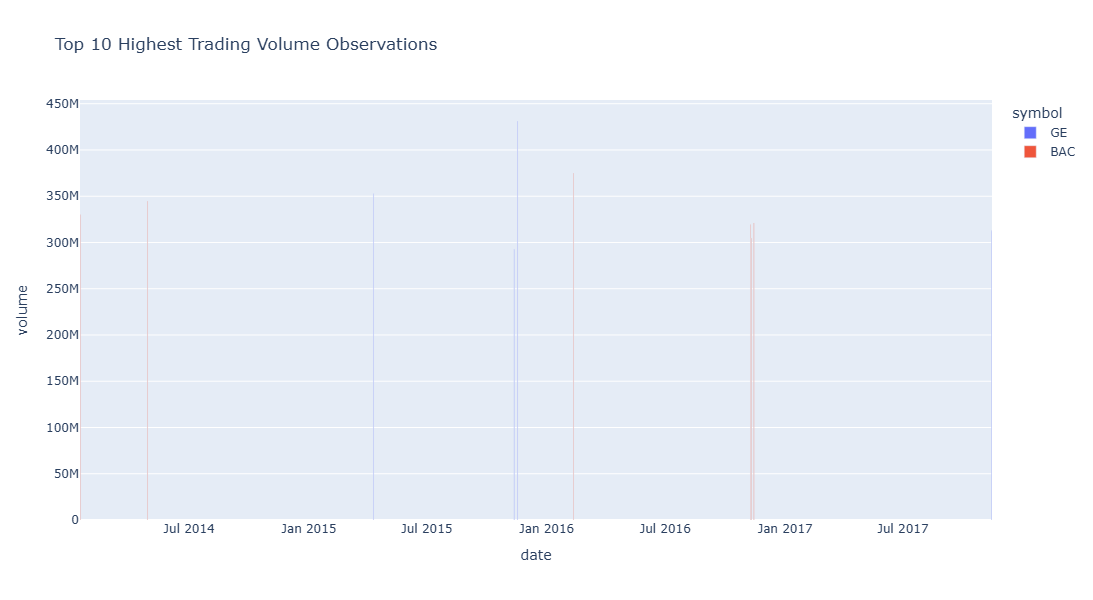

In [96]:
#Highest volume observations
highest_volume = dashboard_data.nlargest(10, 'volume')

fig = px.bar(
    highest_volume,
    x='date',
    y='volume',
    color='symbol',
    title='Top 10 Highest Trading Volume Observations'
)

fig.update_layout(height = 600)
fig.show()

In [94]:
#lowest volume observations
lowest_volume = dashboard_data.nsmallest(10, 'volume')

fig = px.bar(
    lowest_volume,
    x='date',
    y='volume',
    color='symbol',
    title='Top 10 Lowest Trading Volume Observations'
)

fig.update_layout(height = 600)
fig.show()

In [95]:
#Trading volume versus price movements
fig = px.scatter(
    dashboard_data,
    x='volume',
    y='daily_price_change',
    color='symbol',
    title='Trading Volume vs Daily Price Change',
    labels={
        'volume': 'Trading Volume',
        'daily_price_change': 'Daily Price Change ($)'
    }
)

fig.update_layout(height = 600)
fig.show()

### Dashboard validation

In [101]:
# Validation 1: dataset and dashboard KPIs

print("Total stock symbols:", df_clean['symbol'].nunique())
print("Total trading records:", len(df_clean))
print("Start date:", df_clean['date'].min())
print("End date:", df_clean['date'].max())

print("\nSelected dashboard stocks:", dashboard_stocks)
print("Selected stock records:", len(dashboard_data))

print("Average closing price of selected stocks:",
      round(dashboard_data['close'].mean(), 2))

Total stock symbols: 505
Total trading records: 497461
Start date: 2014-01-02 00:00:00
End date: 2017-12-29 00:00:00

Selected dashboard stocks: ['BAC', 'AAPL', 'GE', 'AMD', 'F']
Selected stock records: 5035
Average closing price of selected stocks: 36.42


In [103]:
# 2. Validate daily return calculation

selected_stock = dashboard_stocks[0]

stock_data = dashboard_data[
    dashboard_data['symbol'] == selected_stock
].copy()

stock_data = stock_data.sort_values('date')

stock_data['manual_return'] = (
    (stock_data['close'] - stock_data['close'].shift(1))
    / stock_data['close'].shift(1)
) * 100

print("Selected stock:", selected_stock)

print(stock_data[
    ['date', 'close', 'daily_return', 'manual_return']
].head(10))

returns_match = stock_data['daily_return'].round(6).equals(
    stock_data['manual_return'].round(6)
)

print("Daily returns match:", returns_match)


Selected stock: BAC
            date  close  daily_return  manual_return
59431 2014-01-02  16.10           NaN            NaN
59432 2014-01-03  16.41      1.925466       1.925466
59433 2014-01-06  16.66      1.523461       1.523461
59434 2014-01-07  16.50     -0.960384      -0.960384
59435 2014-01-08  16.58      0.484848       0.484848
59436 2014-01-09  16.83      1.507841       1.507841
59437 2014-01-10  16.77     -0.356506      -0.356506
59438 2014-01-13  16.43     -2.027430      -2.027430
59439 2014-01-14  16.77      2.069385       2.069385
59440 2014-01-15  17.15      2.265951       2.265951
Daily returns match: True


In [104]:
# 3. Validate moving averages


stock_data['manual_ma_7'] = (
    stock_data['close'].rolling(window=7).mean()
)

stock_data['manual_ma_30'] = (
    stock_data['close'].rolling(window=30).mean()
)

print(stock_data[
    ['ma_7', 'manual_ma_7', 'ma_30', 'manual_ma_30']
].tail(10))

ma_7_match = stock_data['ma_7'].round(6).equals(
    stock_data['manual_ma_7'].round(6)
)

ma_30_match = stock_data['ma_30'].round(6).equals(
    stock_data['manual_ma_30'].round(6)
)

print("MA7 calculations match:", ma_7_match)
print("MA30 calculations match:", ma_30_match)


            ma_7  manual_ma_7      ma_30  manual_ma_30
60428  28.957143    28.957143  27.672667     27.672667
60429  29.057143    29.057143  27.728000     27.728000
60430  29.114286    29.114286  27.784667     27.784667
60431  29.191429    29.191429  27.861333     27.861333
60432  29.262857    29.262857  27.962333     27.962333
60433  29.411429    29.411429  28.075333     28.075333
60434  29.561429    29.561429  28.184333     28.184333
60435  29.660000    29.660000  28.295333     28.295333
60436  29.705714    29.705714  28.414000     28.414000
60437  29.715714    29.715714  28.505000     28.505000
MA7 calculations match: True
MA30 calculations match: True


In [105]:
# 4. Validate stock selection

print("\n4. STOCK SELECTION VALIDATION")
print("--------------------------------")

print("Selected stocks:", sorted(dashboard_stocks))
print("Stocks in dashboard data:",
      sorted(dashboard_data['symbol'].unique()))

print("Number of selected stocks:",
      dashboard_data['symbol'].nunique())

stock_selection_match = (
    set(dashboard_stocks) ==
    set(dashboard_data['symbol'].unique())
)

print("Stock selection matches:", stock_selection_match)



4. STOCK SELECTION VALIDATION
--------------------------------
Selected stocks: ['AAPL', 'AMD', 'BAC', 'F', 'GE']
Stocks in dashboard data: ['AAPL', 'AMD', 'BAC', 'F', 'GE']
Number of selected stocks: 5
Stock selection matches: True


In [106]:
# 5. Validate trading volume calculations

average_volume = dashboard_data.groupby(
    'symbol'
)['volume'].mean()

print("Average trading volume by stock:")
print(average_volume.round(2))

print("\nHighest volume observations:")
print(
    dashboard_data.nlargest(10, 'volume')[
        ['date', 'symbol', 'volume']
    ]
)

print("\nLowest volume observations:")
print(
    dashboard_data.nsmallest(10, 'volume')[
        ['date', 'symbol', 'volume']
    ]
)

volume_total = dashboard_data['volume'].sum()

print("\nTotal trading volume:", volume_total)


Average trading volume by stock:
symbol
AAPL    45169571.17
AMD     33289509.07
BAC     89362903.70
F       32914300.94
GE      41443942.52
Name: volume, dtype: float64

Highest volume observations:
             date symbol     volume
195324 2015-11-17     GE  431332632
59962  2016-02-11    BAC  375088650
195170 2015-04-10     GE  352701949
59510  2014-04-28    BAC  344935158
59440  2014-01-15    BAC  330005943
60154  2016-11-14    BAC  320959885
60151  2016-11-09    BAC  319516881
195826 2017-11-14     GE  312556809
60152  2016-11-10    BAC  304986449
195321 2015-11-12     GE  292791614

Lowest volume observations:
            date symbol   volume
32704 2015-11-27    AMD  2606577
32693 2015-11-11    AMD  3532050
32694 2015-11-12    AMD  3576805
32472 2014-12-26    AMD  4029605
32696 2015-11-16    AMD  4149664
32649 2015-09-10    AMD  4290423
32689 2015-11-05    AMD  4302179
32541 2015-04-08    AMD  4348995
32684 2015-10-29    AMD  4500419
32587 2015-06-12    AMD  4557596

Total tradin

In [107]:
# 6. Validate price movement calculations

stock_data['manual_price_change'] = (
    stock_data['close'] - stock_data['close'].shift(1)
)

price_change_match = (
    stock_data['daily_price_change'].round(6).equals(
        stock_data['manual_price_change'].round(6)
    )
)

print(stock_data[
    ['date', 'close', 'daily_price_change',
     'manual_price_change']
].head(10))

print("Daily price changes match:", price_change_match)


            date  close  daily_price_change  manual_price_change
59431 2014-01-02  16.10                 NaN                  NaN
59432 2014-01-03  16.41                0.31                 0.31
59433 2014-01-06  16.66                0.25                 0.25
59434 2014-01-07  16.50               -0.16                -0.16
59435 2014-01-08  16.58                0.08                 0.08
59436 2014-01-09  16.83                0.25                 0.25
59437 2014-01-10  16.77               -0.06                -0.06
59438 2014-01-13  16.43               -0.34                -0.34
59439 2014-01-14  16.77                0.34                 0.34
59440 2014-01-15  17.15                0.38                 0.38
Daily price changes match: True


In [109]:
# 7. Final validation summary

print("Daily returns:", returns_match)
print("MA7:", ma_7_match)
print("MA30:", ma_30_match)
print("Stock selection:", stock_selection_match)
print("Daily price changes:", price_change_match)




Daily returns: True
MA7: True
MA30: True
Stock selection: True
Daily price changes: True
